# 3: Sai phân & kiểm định lại:
– Sai phân bậc 1

– Vẽ lại đồ thị chuỗi sau sai phân

– Kiểm định ADF lần 2
 
 Câu hỏi cần trả lời:

– Sau sai phân, chuỗi đã dừng chưa?

– Giá trị d trong ARIMA là bao nhiêu?

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from pathlib import Path

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

In [11]:
data_path = Path("../data/raw/a10.csv")

if not data_path.exists():
    data_path = Path("data/raw/a10.csv")

if not data_path.exists():
    raise FileNotFoundError(
        "Không tìm thấy a10.csv. "
        "Hãy kiểm tra lại thư mục data/raw."
    )

df = pd.read_csv(data_path)

print("Kích thước dữ liệu:", df.shape)
print("Tên cột:", df.columns.tolist())

display(df.head())

Kích thước dữ liệu: (204, 2)
Tên cột: ['date', 'value']


,date,value
0,1991-07-01,3.526591
1,1991-08-01,3.180891
2,1991-09-01,3.252221
3,1991-10-01,3.611003
4,1991-11-01,3.565869


# 1.Thực hiện sai phân bậc 1

In [14]:
# Công thức sai phân: Y'_t = Y_t - Y_{t-1}
df_diff = df['value'].diff().dropna()

# Xem dữ liệu sau khi sai phân
df_diff.head()

1   -0.345700
2    0.071330
3    0.358782
4   -0.045134
5    0.740502
Name: value, dtype: float64

# 2.Kiểm định ADF trên chuỗi sau sai phân

In [15]:
# Chạy kiểm định ADF
adf_result = adfuller(df_diff)

# In kết quả kiểm định
print("=== KẾT QUẢ KIỂM ĐỊNH ADF CHO CHUỖI SAI PHÂN BẬC 1 ===")
print(f"ADF Statistic  : {adf_result[0]:.4f}")
print(f"p-value        : {adf_result[1]:.4f}")
print(f"Lags Used      : {adf_result[2]}")
print(f"Observations   : {adf_result[3]}")
print("Critical Values:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value:.4f}")

=== KẾT QUẢ KIỂM ĐỊNH ADF CHO CHUỖI SAI PHÂN BẬC 1 ===
ADF Statistic  : -2.4952
p-value        : 0.1167
Lags Used      : 15
Observations   : 187
Critical Values:
   1%: -3.4658
   5%: -2.8771
   10%: -2.5751


C:\Users\PC\AppData\Local\Temp\ipykernel_16188\1566649253.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df_diff)


# 3.Vẽ biểu đồ so sánh Chuỗi gốc vs Chuỗi sau sai phân

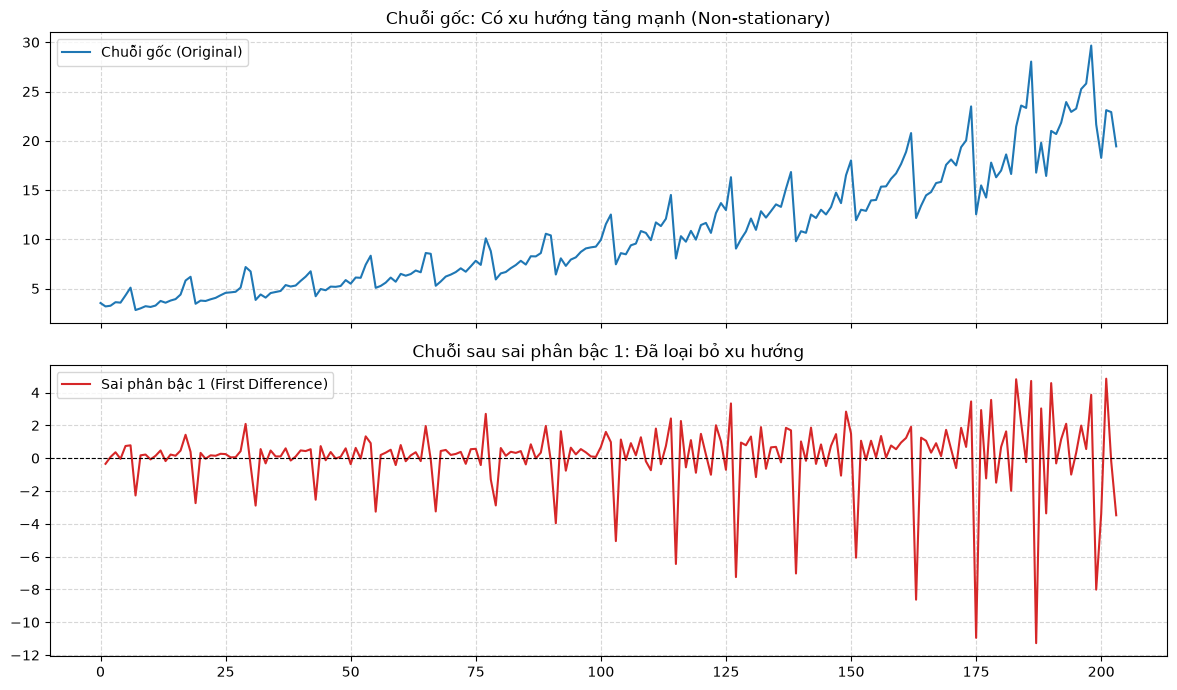

In [16]:
# Khởi tạo khung vẽ 2 đồ thị
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Đồ thị 1: Chuỗi gốc
axes[0].plot(df['value'], color='tab:blue', label='Chuỗi gốc (Original)')
axes[0].set_title('Chuỗi gốc: Có xu hướng tăng mạnh (Non-stationary)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper left')

# Đồ thị 2: Chuỗi sau sai phân bậc 1
axes[1].plot(df_diff, color='tab:red', label='Sai phân bậc 1 (First Difference)')
axes[1].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[1].set_title('Chuỗi sau sai phân bậc 1: Đã loại bỏ xu hướng', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()